In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..") if os.path.basename(os.getcwd()) == "5" else os.getcwd())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

if 'google.colab' in str(get_ipython()):
    print("Google Colab 環境を検出しました。環境構築を開始します...")
    if not os.path.exists("study-mikanos"):
        !git clone https://github.com/miyayudai/study-mikanos.git
    %cd study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    !cmake -B build -S . > /dev/null && cmake --build build --target ch05_separate_compilation_sim > /dev/null
    print("セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    print(f"ローカル実行環境です。(リポジトリルート: {repo_root})")


ローカル実行環境です。(リポジトリルート: /home/student/Documents/GitHub/study-mikanos)


# 5.2 分割コンパイル (`Separate Compilation & Linking`)

### はじめに：単一巨大ソースファイル（Monolithic Source File）の崩壊とモジュール化の必然性

前節（[5.1 文字を書いてみる](5.1_Drawing_Characters_and_References.ipynb)）までの MikanOS カーネル開発では、フレームバッファ描画クラス（`PixelWriter`, `RGBResv8BitPerColorPixelWriter`, `BGRResv8BitPerColorPixelWriter`）、ビットマップフォントデータ（`kFontA`）、文字描画関数（`WriteAscii`）、配置 new 演算子、そしてエントリポイントである `KernelMain` に至るまで、**すべてのコードを単一の `kernel/main.cpp` に書き連ねていました**。

OS 自作の初期段階（第3章・第4章）では、ファイルが1つであることはビルド手順がシンプル（`clang++ -c main.cpp` のみ）であり、全体の把握も容易であるという利点がありました。しかし、OS に文字表示、マウス入力、割り込みハンドラ、メモリ管理、マルチタスク、ファイルシステムと機能を追加していくにつれて、単一ファイル構成は以下のような**致命的な開発上の破綻**を引き起こします：

1. **可読性と凝集度（Cohesion）の喪失**:
   画面描画アルゴリズム、ハードウェア固有のフォント展開、OS の起動フローという全く異なる抽象度・関心事（*Separation of Concerns*）が渾然一体となり、コードの探索や保守が不可能になります。
2. **インクリメンタルビルド（Incremental Build）の完全な無効化**:
   フォントのピクセル形状を 1 ビット修正しただけで、カーネル全体の `main.cpp` を丸ごと再コンパイルしなければなりません。将来的にカーネルコードが数万行〜数十万行に達したとき、わずかな修正に対するビルド待ち時間が数分〜数十分にも及ぶことになります。
3. **チーム開発や再利用性の遮断**:
   「描画処理だけを単体テストしたい」「将来のブートローダや別ドライバでも `PixelWriter` を再利用したい」といった場合に、`main.cpp` から関数をコピペするか、無駄な依存関係ごと引き連れてくるしかなくなります。

本節（`osbook_day05b`）では、肥大化を始めたカーネルコードを役割ごとに**複数のヘッダファイル（`.hpp`）とソースファイル（`.cpp`）に分割**し、現代の C++ および低レイヤ開発における中核技術である**「分割コンパイル（Separate Compilation）」**と**「リンカ（Linker）によるシンボル解決（Symbol Resolution）」**、さらには**「Makefile の自動依存関係追跡（Dependency Generation）」**の動作原理を、ビット・ELFバイナリ・アセンブリレベルで徹底的に解剖します。

## 1. 翻訳単位（Translation Unit）とコンパイル・リンクパイプライン

C++ プログラムが機械語バイナリ（ELF 実行可能ファイル）として完成するまでには、**「プリプロセス（Preprocess）」「コンパイル（Compile）」「リンク（Link）」** という 3 段階のパイプラインが存在します。このうち、分割コンパイルを理解する上で最も根幹となる概念が **翻訳単位（Translation Unit）** です。

### 翻訳単位（Translation Unit）の数学的・工学的定義

> [!IMPORTANT]
> **翻訳単位（Translation Unit）とは**:
> 1つのソースファイル（例: `graphics.cpp`）に対し、C/C++ プリプロセッサが `#include` されたすべてのヘッダファイルの内容を再帰的に展開し、`#define` マクロを置換し、`#ifdef` 条件付きコンパイルを処理した後に得られる、**「純粋な C++ ソースコードの単一のトークン列」** のことです。

コンパイラ（`clang++ -c`）は、**各翻訳単位を完全に独立した世界として 1 つずつ処理**します。
- `clang++ -c graphics.cpp` を実行している瞬間、コンパイラは `font.cpp` や `main.cpp` の存在を一切知りません。
- したがって、`graphics.cpp` の中で別の場所（例: `main.cpp`）にある関数や変数を利用したい場合、**「その関数の名前、引数の型、戻り値の型（シグネチャ）」** をあらかじめコンパイラに宣言（Declaration）しておかなければ、コンパイルエラー（`use of undeclared identifier`）となります。

```mermaid
flowchart TD
    subgraph SourceFiles [ソースファイル群]
        GH["graphics.hpp (宣言)"]
        GC["graphics.cpp (定義)"]
        FH["font.hpp (宣言)"]
        FC["font.cpp (定義)"]
        MC["main.cpp (利用側)"]
    end

    subgraph TranslationUnits [翻訳単位 (プリプロセス後)]
        TUG["翻訳単位 1: graphics.cpp + graphics.hpp"]
        TUF["翻訳単位 2: font.cpp + font.hpp + graphics.hpp"]
        TUM["翻訳単位 3: main.cpp + graphics.hpp + font.hpp"]
    end

    subgraph RelocatableObjects [リロケータブル・オブジェクト (.o)]
        OG["graphics.o<br/>[T] RGB/BGRPixelWriter::Write<br/>[R] vtable"]
        OF["font.o<br/>[T] WriteAscii<br/>[r] kFontA"]
        OM["main.o<br/>[T] KernelMain<br/>[U] WriteAscii, vtable"]
    end

    subgraph FinalBinary [最終実行バイナリ]
        ELF["kernel.elf (64-bit ELF)<br/>全シンボルが物理アドレスに結合"]
    end

    GC -->|clang++ -E| TUG
    GH -.->|#include| TUG
    FC -->|clang++ -E| TUF
    FH -.->|#include| TUF
    GH -.->|#include| TUF
    MC -->|clang++ -E| TUM
    GH -.->|#include| TUM
    FH -.->|#include| TUM

    TUG -->|clang++ -c| OG
    TUF -->|clang++ -c| OF
    TUM -->|clang++ -c| OM

    OG -->|ld.lld (シンボル解決 & リロケーション)| ELF
    OF -->|ld.lld| ELF
    OM -->|ld.lld| ELF
```

## 2. 宣言（Declaration） vs 定義（Definition）と単一定義規則（ODR）

分割コンパイルを正しく行うための最重要原則が、**「宣言（Declaration）」と「定義（Definition）」の厳格な分離**です。

### 宣言（Declaration）の役割
- **宣言**とは、「このような名前と型を持つ関数／変数／クラスが存在する」という仕様情報をコンパイラに伝える行為です。
- **メモリ割り当てや機械語コードの生成を一切行いません**。
- 関数のプロトタイプ宣言（例: `void WriteAscii(PixelWriter& writer, int x, int y, char c, const PixelColor& color);`）や、クラスのメンバ関数宣言がこれに該当します。
- 宣言は型チェックと関数呼び出しコード（引数をレジスタ `RDI, RSI, RDX...` に積むコード）を生成するために十分な情報を提供します。

### 定義（Definition）の役割
- **定義**とは、関数の本体（機械語コードを生成する `{ ... }` ブロック）や、変数に対する実際のメモリ領域（`.data` や `.bss` セクション）を確定させる行為です。
- **オブジェクトファイル内に実体（シンボル）を生成します**。

| 対象 | 宣言（Declaration）の例 (ヘッダ `.hpp` に記述) | 定義（Definition）の例 (ソース `.cpp` に記述) |
|---|---|---|
| **関数** | `void WriteAscii(...);` (セミコロンで終了) | `void WriteAscii(...) { for (...) { ... } }` (関数本体) |
| **グローバル変数** | `extern int g_cursor_x;` (`extern` 指定) | `int g_cursor_x = 0;` (メモリ確保) |
| **クラス／構造体** | `class PixelWriter;` (前方宣言: 不完全型) | `class PixelWriter { int w; ... };` (メンバ定義: 完全型) |
| **メンバ関数** | `virtual void Write(...) = 0;` | `void RGBPixelWriter::Write(...) { ... }` |

### なぜヘッダにクラスの定義（メンバ変数一覧）を書くのか？
> [!NOTE]
> 「関数は宣言だけヘッダに書くのに、なぜ `class PixelWriter { ... };` はヘッダに書くのか？」という疑問が生じます。
> これは、利用側（`main.cpp`）が `PixelWriter` のポインタ間接参照や配置 new（`sizeof(RGBResv8BitPerColorPixelWriter)`）を行う際、**オブジェクトのバイトサイズやメンバ変数のメモリレイアウト（オフセット）、vtable のポインタ位置がコンパイル時に確定している必要があるから**です。

---

### 単一定義規則（One Definition Rule: ODR）
C++ 標準規格における最も根本的なルールが **ODR（One Definition Rule）** です：

1. **単一翻訳単位内**: いかなる変数・関数・クラス・列挙型も、1つの翻訳単位内で 2 回以上定義されてはならない。
2. **プログラム全体（リンク全体）**: 非インラインの関数やグローバル変数は、**プログラム全体（すべてのオブジェクトファイルを合わせた全体）で厳密に 1 つだけ定義されていなければならない**。

もしヘッダファイル（`.hpp`）に関数本体（定義）を書いてしまうと、そのヘッダを `#include` したすべての `.cpp` ファイル（翻訳単位）がそれぞれ同じ関数シンボルを生成してしまいます。その結果、リンク時にリンカが **`ld.lld: error: duplicate symbol: WriteAscii`** という ODR 違反エラーを吐いて停止します。

## 3. インクルードガード（Include Guard）と `#pragma once` の本質

ヘッダファイルを分割していくと、**「ヘッダファイルが別のヘッダファイルをインクルードする」** という多重インクルード（Nested Include）が必然的に発生します。

例えば MikanOS `day05b` では：
- `graphics.hpp` は `frame_buffer_config.hpp` を include しています（`PixelWriter` が `FrameBufferConfig` をメンバに持つため）。
- `font.hpp` は `graphics.hpp` を include しています（`WriteAscii` が `PixelWriter` と `PixelColor` を引数に取るため）。
- `main.cpp` は、画面描画と文字描画の両方を行うため、`graphics.hpp` と `font.hpp` の両方を include します。

このとき、プリプロセッサの include 展開を素朴に行うと、`main.cpp` の中に `graphics.hpp` の内容が **2 回展開** されてしまいます！

### 単一翻訳単位内でのクラス多重定義エラー
クラスの定義（`struct PixelColor { ... };` や `class PixelWriter { ... };`）は、同一翻訳単位内で 2 回現れるとコンパイルエラー（`redefinition of 'PixelColor'`）になります。

これを防止する仕組みが **インクルードガード（Include Guard）** です。

#### 1. 伝統的インクルードガード（Classic Macro Guard）
```cpp
#ifndef GRAPHICS_HPP_
#define GRAPHICS_HPP_

// ヘッダの内容

#endif // GRAPHICS_HPP_
```
- 1回目の include 時は `GRAPHICS_HPP_` マクロが未定義なので `#ifndef` を通過し、直後に `#define GRAPHICS_HPP_` で定義。
- 2回目の include 時は既に定義済みなので `#endif` まで丸ごとスキップされます。

#### 2. 現代的インクルードガード：`#pragma once`
```cpp
#pragma once

// ヘッダの内容
```
- C++ プリプロセッサに対するコンパイラ指示子（Directive）です。
- コンパイラはファイルパスや inode 番号を内部テーブルで記憶し、同一翻訳単位内で同一ファイルが 2 回目以降に include された場合、**ディスクからのファイル読み込み自体を即座にスキップ** します。
- マクロ名重複の心配がなく、ファイルが短くなり、プリプロセス速度も向上するため、MikanOS では `#pragma once` が全面採用されています。

---

### 【極めて重要な落とし穴】`#pragma once` は ODR 違反を防げるか？

> [!WARNING]
> **初心者が最も陥りやすい誤解**:
> 「`#pragma once` を書いてあるから、ヘッダに関数実装（定義）を書いても重複しないはずだ」
>
> **これは完全に間違いです！**
> `#pragma once` は、あくまで **「1つの翻訳単位（1つの `.cpp`）の中で」** 同じヘッダが複数回展開されるのを防ぐプリプロセッサ機能にすぎません。
> 異なる翻訳単位（`font.cpp` と `main.cpp`）がそれぞれ `#include "font.hpp"` した場合、プリプロセッサは双方の `.cpp` にその関数定義を展開します。
> その結果、`font.o` にも `main.o` にも同一関数の機械語コードとシンボルが生成され、**リンク段階でリンカが多重定義エラー（ODR 違反）を起こします**。
>
> したがって、**「ヘッダには宣言のみ、定義は `.cpp` に書く」** という分離原則が絶対不可欠なのです。

## 4. 高解像度アーキテクチャ図版 (Figure 5.3) の徹底解剖

下図は、MikanOS `day05b` における分割コンパイル・翻訳単位・シンボルテーブル・リンカによるアドレス解決の全貌を可視化したものです（DPI 300 高解像度図版）。

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:18874: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


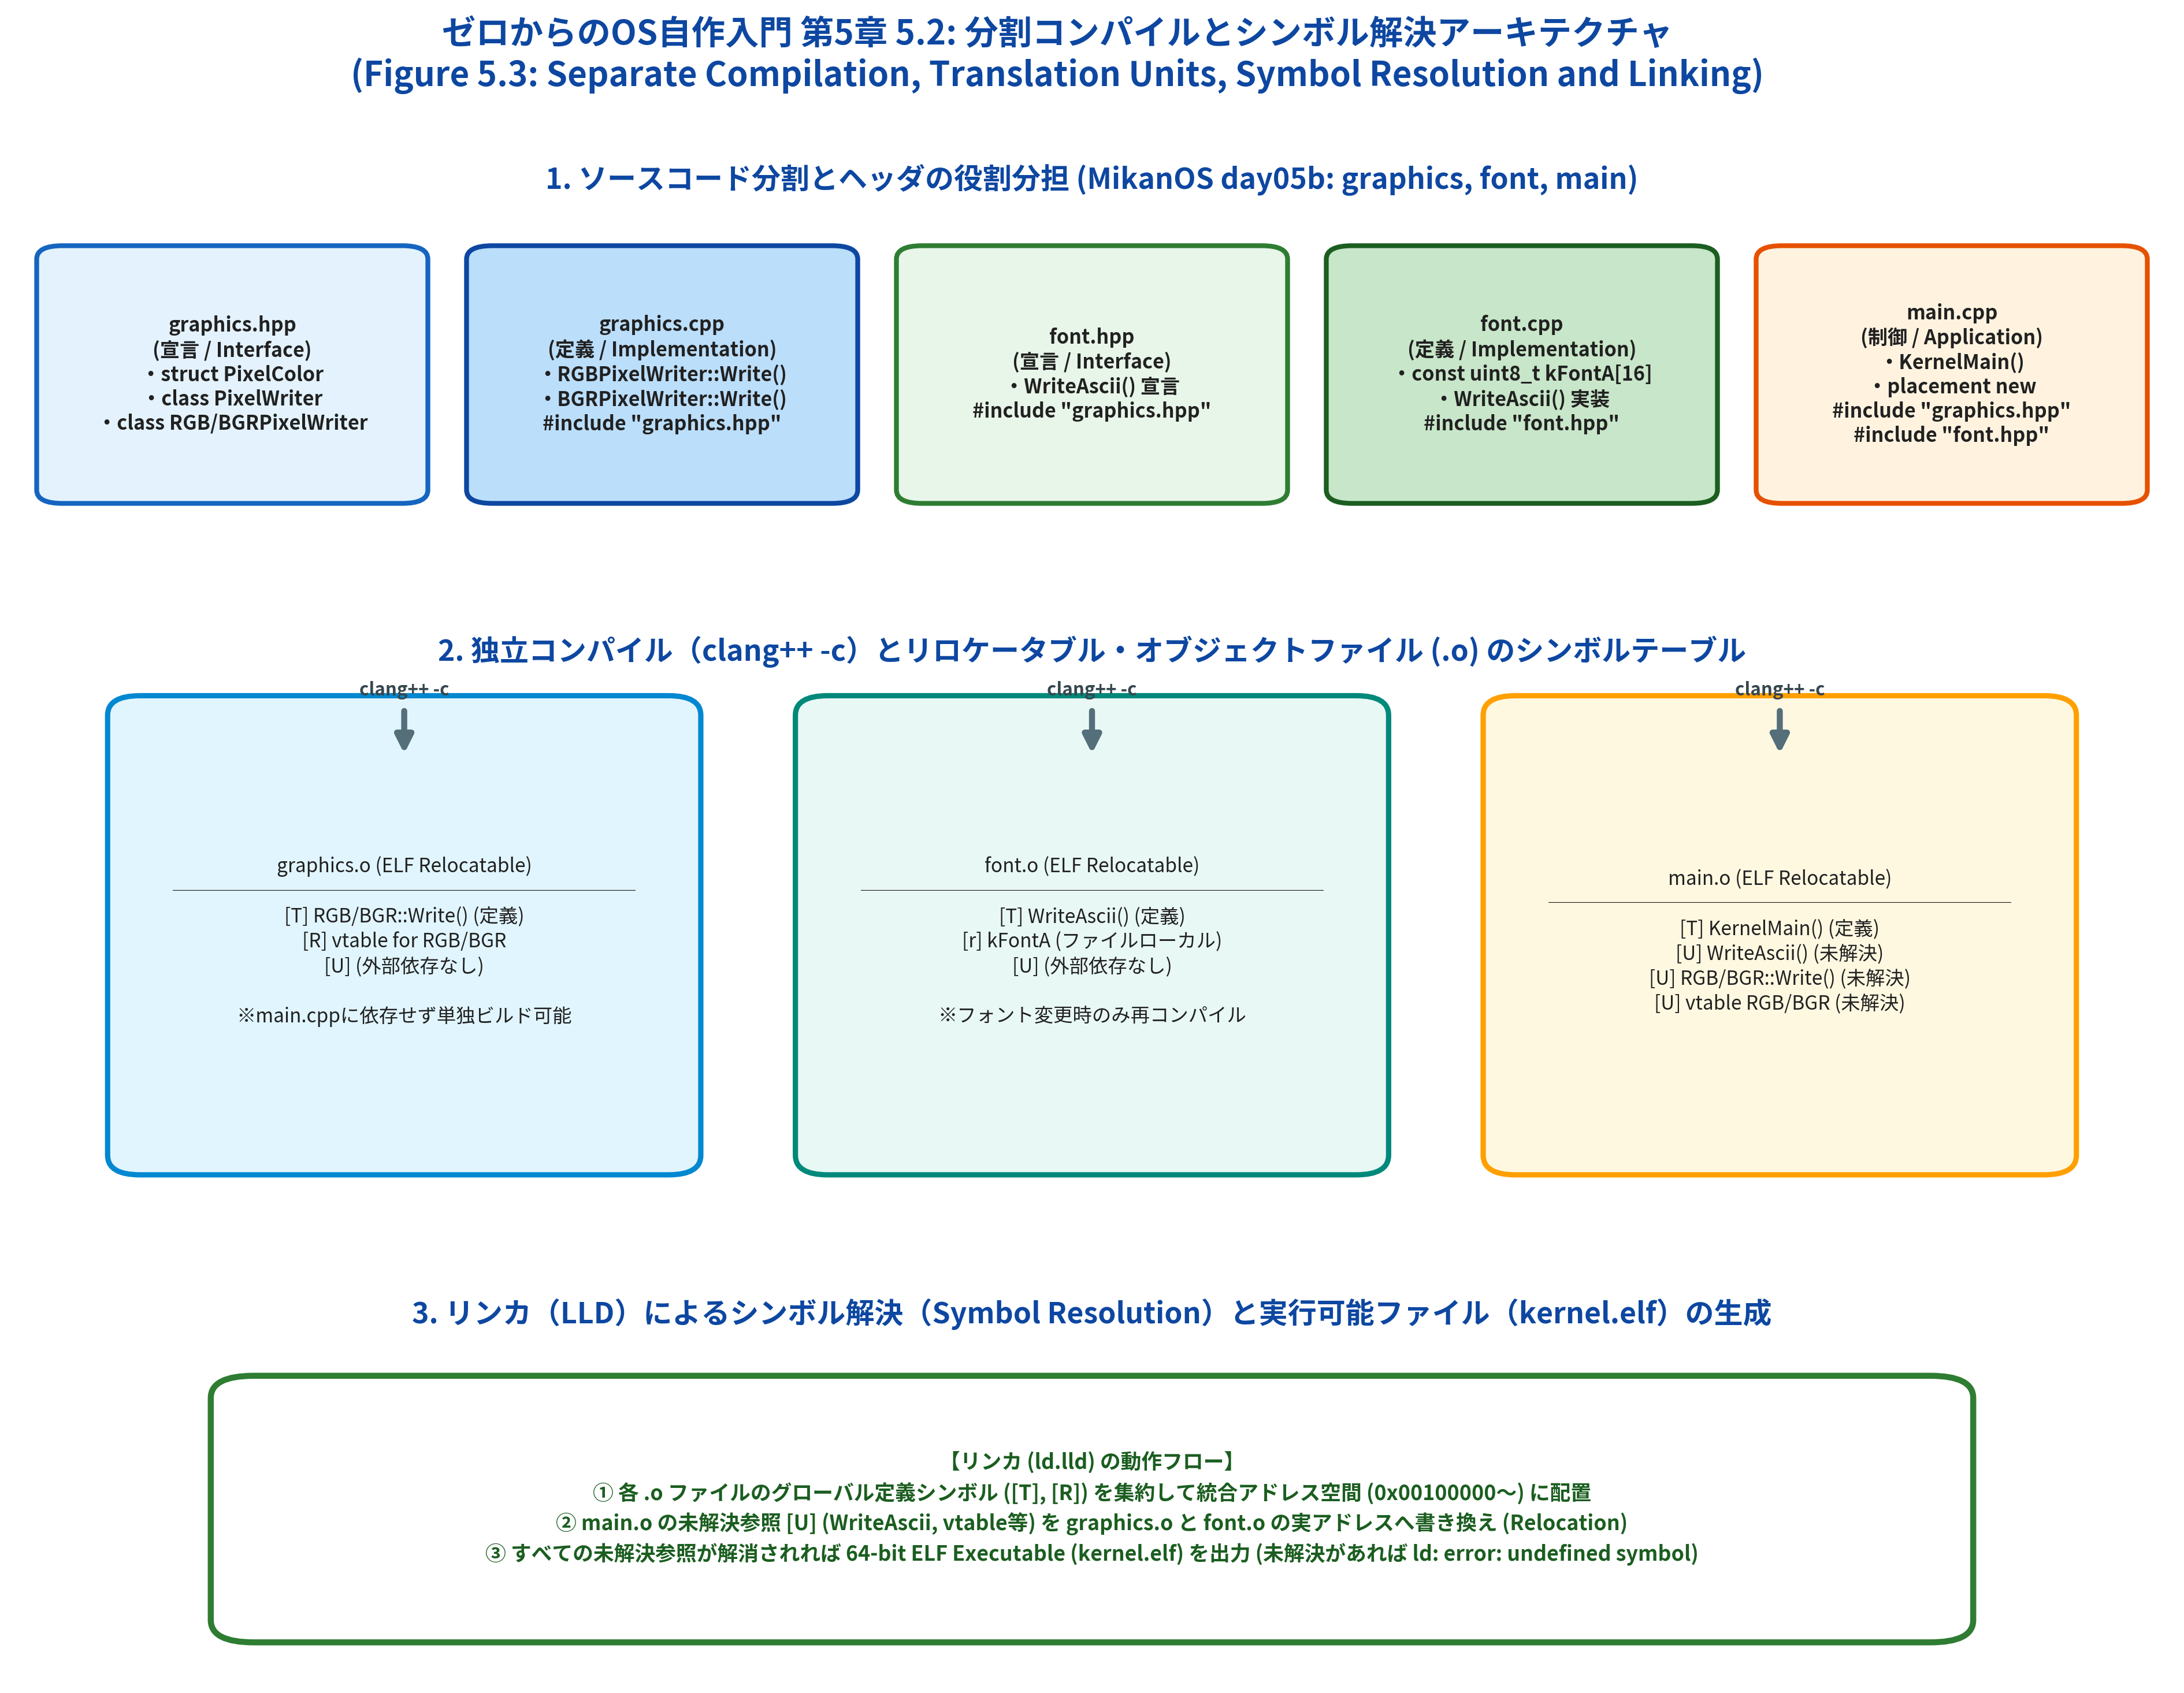

In [2]:
import os
from IPython.display import Image, display
from common import plot_fig5_03_separate_compilation_and_linking_pipeline

fig5_03_path = os.path.join(repo_root, "5/result/fig5_03_separate_compilation_and_linking_pipeline.png")
plot_fig5_03_separate_compilation_and_linking_pipeline(fig5_03_path)
display(Image(filename=fig5_03_path, width=950))


## 5. MikanOS `day05b` における分割設計（`graphics`, `font`, `main`）

公式リポジトリ（`uchan-nos/mikanos`）のコミット差分 `osbook_day05a..osbook_day05b` に基づき、どのようにファイルが分割されたかを具体的に確認します。

### 1. `kernel/graphics.hpp` (描画インターフェース宣言)
```cpp
#pragma once
#include "frame_buffer_config.hpp"

struct PixelColor {
  uint8_t r, g, b;
};

class PixelWriter {
 public:
  PixelWriter(const FrameBufferConfig& config) : config_{config} {}
  virtual ~PixelWriter() = default;
  virtual void Write(int x, int y, const PixelColor& c) = 0;

 protected:
  uint8_t* PixelAt(int x, int y) {
    return config_.frame_buffer + 4 * (config_.pixels_per_scan_line * y + x);
  }

 private:
  const FrameBufferConfig& config_;
};

class RGBResv8BitPerColorPixelWriter : public PixelWriter {
 public:
  using PixelWriter::PixelWriter;
  virtual void Write(int x, int y, const PixelColor& c) override;
};

class BGRResv8BitPerColorPixelWriter : public PixelWriter {
 public:
  using PixelWriter::PixelWriter;
  virtual void Write(int x, int y, const PixelColor& c) override;
};
```
- `PixelWriter::PixelAt` のような極めて軽量なインラインヘルパーや純粋仮想関数はクラス定義内に記述できます。
- 派生クラス `RGBResv8BitPerColorPixelWriter::Write` は仮想関数のシグネチャのみ宣言し、本体は `graphics.cpp` に委ねます。

### 2. `kernel/graphics.cpp` (描画実装)
```cpp
#include "graphics.hpp"

void RGBResv8BitPerColorPixelWriter::Write(int x, int y, const PixelColor& c) {
  auto p = PixelAt(x, y);
  p[0] = c.r;
  p[1] = c.g;
  p[2] = c.b;
}

void BGRResv8BitPerColorPixelWriter::Write(int x, int y, const PixelColor& c) {
  auto p = PixelAt(x, y);
  p[0] = c.b;
  p[1] = c.g;
  p[2] = c.r;
}
```
- 実装ファイル冒頭で自己のヘッダ `#include "graphics.hpp"` をインクルードします。
- これにより、ヘッダ自体に構文エラーや未定義型参照（自己完結性の欠如）がないかを、この `.cpp` をコンパイルするだけで検証できます（*Self-contained Header Principle*）。

### 3. `kernel/font.hpp` (フォント描画インターフェース宣言)
```cpp
#pragma once
#include <cstdint>
#include "graphics.hpp"

void WriteAscii(PixelWriter& writer, int x, int y, char c, const PixelColor& color);
```
- `WriteAscii` 関数の完全なシグネチャ（引数の型・名前、戻り値型）のみを宣言。

### 4. `kernel/font.cpp` (フォントデータと描画実装)
```cpp
#include "font.hpp"

const uint8_t kFontA[16] = {
  0b00000000,
  0b00011000,
  // ...
};

void WriteAscii(PixelWriter& writer, int x, int y, char c, const PixelColor& color) {
  if (c != 'A') return;
  for (int dy = 0; dy < 16; ++dy) {
    for (int dx = 0; dx < 8; ++dx) {
      if ((kFontA[dy] << dx) & 0x80u) {
        writer.Write(x + dx, y + dy, color);
      }
    }
  }
}
```
- `kFontA` 配列は `font.cpp` の内部でのみ使用されるため、ヘッダには公開せずソースファイル内に局所化されています（内部リンケージ）。

### 5. `kernel/main.cpp` (エントリポイントへの凝縮)
```cpp
#include "frame_buffer_config.hpp"
#include "graphics.hpp"
#include "font.hpp"

void* operator new(size_t size, void* buf) { return buf; }
void operator delete(void* p) noexcept {}

extern "C" void KernelMain(const FrameBufferConfig& frame_buffer_config) {
  // ... 描画インスタンス生成と画面塗りつぶし ...
  WriteAscii(*pixel_writer, 50, 50, 'A', {0, 0, 0});
  WriteAscii(*pixel_writer, 58, 50, 'A', {0, 0, 0});
  while (1) __asm__("hlt");
}
```
- `main.cpp` から雑多な描画ロジックが消え、わずか数十行のエントリポイント処理に洗練されました！

## 6. シンボルテーブル（Symbol Table）とリンカによるアドレス解決

コンパイルによって生成されたオブジェクトファイル（`.o`）の内部構造を調べると、リンカがどのようにこれらを結合するかが一目瞭然となります。Linux / LLVM 環境の **`nm` コマンド** を使うと、オブジェクトファイルのシンボル一覧を表示できます。

### `nm` 出力のシンボル種別フラグの意味
- **`T` / `t` (Text Section)**: コード領域（関数）。大文字 `T` は外部公開（Global / External Linkage）、小文字 `t` はファイル内部限定（Static / Internal Linkage）。
- **`R` / `r` (ReadOnly Data Section)**: 定数データや vtable、文字列表面リテラル。
- **`D` / `d` (Data Section)**: 初期化された大域変数。
- **`B` / `b` (BSS Section)**: 未初期化の大域変数（起動時にゼロクリアされる領域）。
- **`U` (Undefined)**: **未解決シンボル**。この翻訳単位内で参照（呼び出し）されているが、実体はこのファイル内に存在しない外部シンボル。

### `day05b` 各オブジェクトファイルのシンボルテーブル比較

```
$ nm --demangle graphics.o
0000000000000000 T RGBResv8BitPerColorPixelWriter::Write(int, int, PixelColor const&)
0000000000000030 T BGRResv8BitPerColorPixelWriter::Write(int, int, PixelColor const&)
0000000000000000 R vtable for RGBResv8BitPerColorPixelWriter
0000000000000020 R vtable for BGRResv8BitPerColorPixelWriter

$ nm --demangle font.o
0000000000000000 T WriteAscii(PixelWriter&, int, int, char, PixelColor const&)
0000000000000000 r kFontA

$ nm --demangle main.o
0000000000000000 T KernelMain
                 U RGBResv8BitPerColorPixelWriter::Write(int, int, PixelColor const&)
                 U BGRResv8BitPerColorPixelWriter::Write(int, int, PixelColor const&)
                 U vtable for RGBResv8BitPerColorPixelWriter
                 U vtable for BGRResv8BitPerColorPixelWriter
                 U WriteAscii(PixelWriter&, int, int, char, PixelColor const&)
```

### リンカ（`ld.lld`）の解決アルゴリズム（Pass 1 & Pass 2）
1. **Pass 1 (シンボル集約)**: 各 `.o` の定義シンボル（`T`, `R`, `D`, `B`）を集め、アドレスマップ上に配置して仮想アドレス（例: `0x00100000` 以降）を確定します。このとき同一のグローバルシンボルが複数見つかれば即座に ODR 違反エラー（`duplicate symbol`）を発行します。
2. **Pass 2 (リロケーション / 未解決参照の解決)**: 各 `.o` にある未解決参照 `U` に対し、Pass 1 で確定した相手先のアドレスを機械語命令（`CALL rel32` やメモリ参照オフセット）に直接書き込みます（**リロケーション: Relocation**）。すべての `U` が解消されれば `kernel.elf` が正常出力されます。

## 7. 高解像度アーキテクチャ図版 (Figure 5.4) の徹底解剖

下図は、ヘッダ依存関係有向非巡回グラフ（DAG）、Makefile による `-MM` 自動依存関係生成メカニズム、および ODR とインクルードガードの本質的境界を可視化したものです（DPI 300 高解像度図版）。

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:19015: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


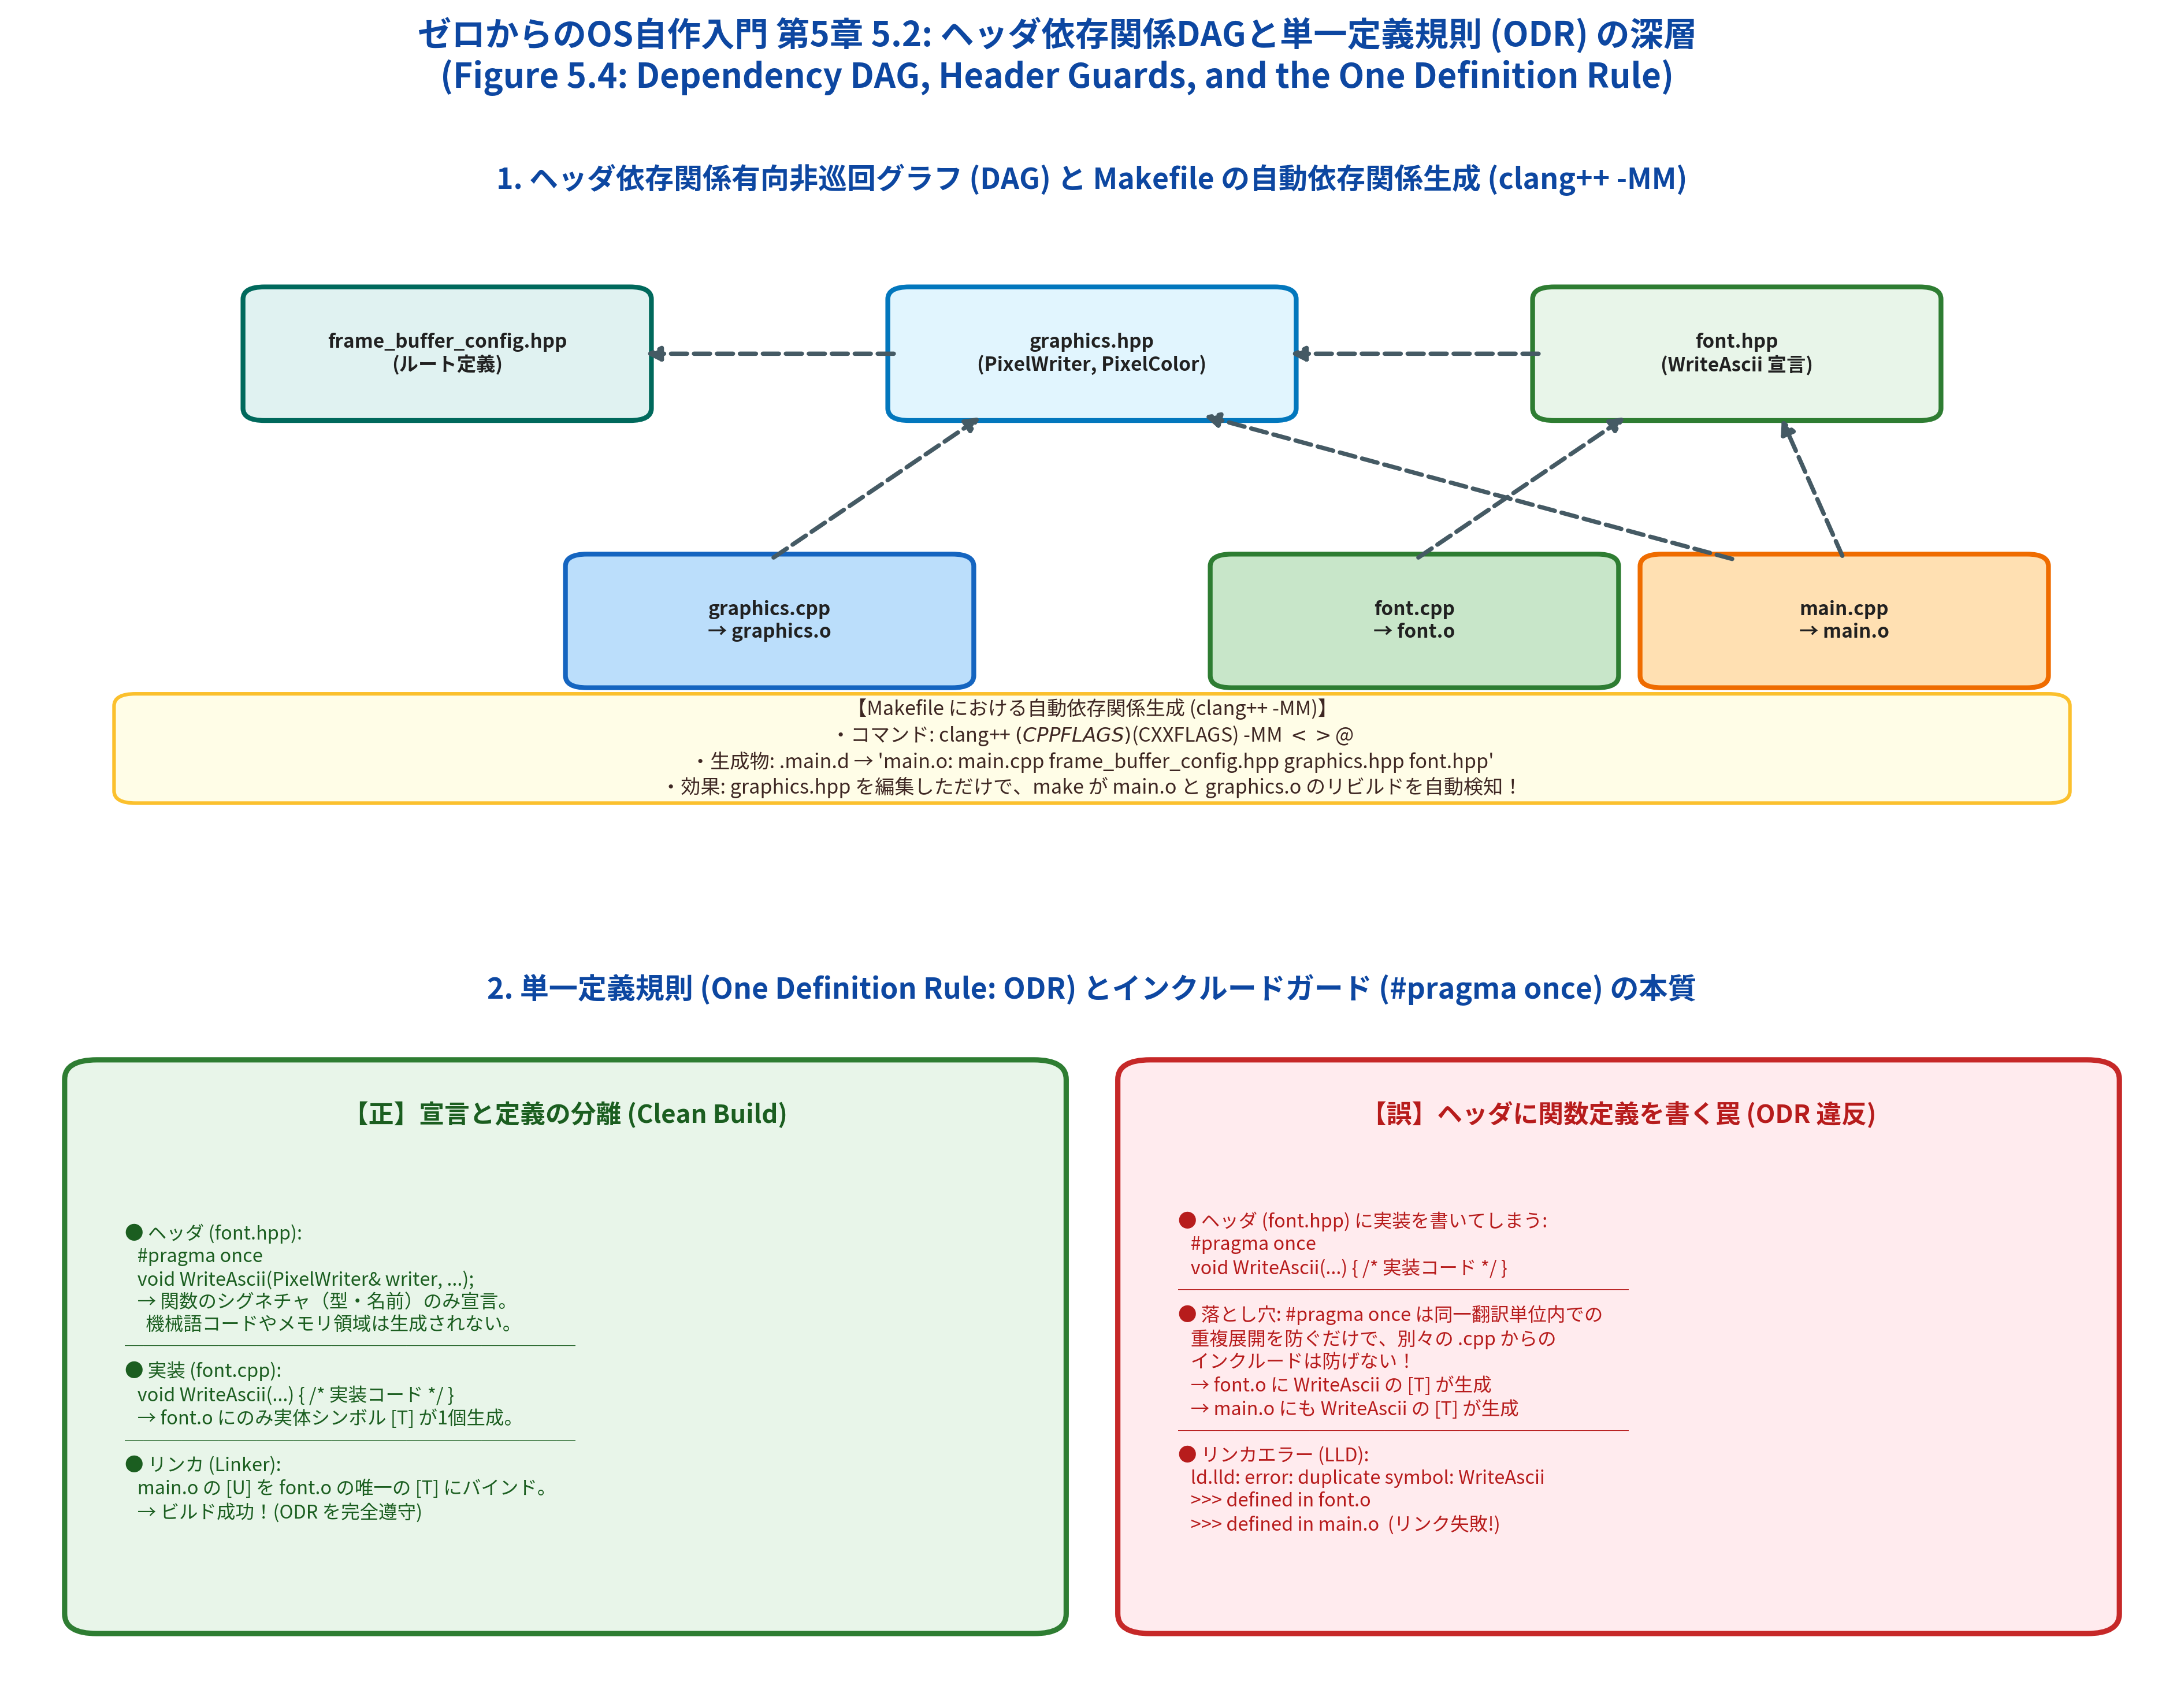

In [3]:
import os
from IPython.display import Image, display
from common import plot_fig5_04_header_dependency_graph_and_odr

fig5_04_path = os.path.join(repo_root, "5/result/fig5_04_header_dependency_graph_and_odr.png")
plot_fig5_04_header_dependency_graph_and_odr(fig5_04_path)
display(Image(filename=fig5_04_path, width=950))


## 8. Makefile の洗練化と依存関係自動生成（`clang++ -MM`）

複数ファイル構成になったことで、`Makefile` のビルドスクリプトも劇的な進化を遂げます。

### `kernel/Makefile` の全容（`day05b`）
```makefile
TARGET = kernel.elf
OBJS = main.o graphics.o font.o
DEPENDS = $(join $(dir $(OBJS)),$(addprefix .,$(notdir $(OBJS:.o=.d))))

CXXFLAGS += -O2 -Wall -g --target=x86_64-elf -ffreestanding -mno-red-zone \
            -fno-exceptions -fno-rtti -std=c++17
LDFLAGS  += --entry KernelMain -z norelro --image-base 0x100000 --static

.PHONY: all
all: $(TARGET)

.PHONY: clean
clean:
	rm -rf *.o

kernel.elf: $(OBJS) Makefile
	ld.lld $(LDFLAGS) -o kernel.elf $(OBJS)

%.o: %.cpp Makefile
	clang++ $(CPPFLAGS) $(CXXFLAGS) -c $<

.%.d: %.cpp
	clang++ $(CPPFLAGS) $(CXXFLAGS) -MM $< > $@
	$(eval OBJ = $(<:.cpp=.o))
	sed --in-place 's|$(notdir $(OBJ))|$(OBJ)|' $@

.PHONY: depends
depends:
	$(MAKE) $(DEPENDS)

-include $(DEPENDS)
```

### Makefile 改良の中核ポイント

#### 1. 複数オブジェクトのリンク（`OBJS = main.o graphics.o font.o`）
`kernel.elf` の必須条件（Prerequisite）に `$(OBJS)` を指定することで、Make は 3 つの `.cpp` からそれぞれ `.o` を生成し、最後に `ld.lld` で 1 つの実行ファイルに結合します。

#### 2. ヘッダ依存関係の盲点と危険性
素朴な Makefile ルール `%.o: %.cpp` では、**「ヘッダファイルを編集しても `.o` が再生成されない」** という致命的な欠陥があります。
- 例: `graphics.hpp` の `PixelColor` 構造体に新メンバを追加しても、`main.cpp` そのものの最終更新日時は変化しないため、Make は「`main.o` は最新である」と判断して再コンパイルをスキップします。
- その結果、`graphics.o` と `main.o` で構造体のオフセット認識が食い違うという、極めて追跡困難な怪奇バグが発生します。

#### 3. `clang++ -MM` による依存関係自動生成（`.%.d`）
`clang++ -MM main.cpp` を実行すると、コンパイラ自身がソースコードを解析し、以下のような Makefile 形式の依存関係を出力してくれます：
```makefile
main.o: main.cpp frame_buffer_config.hpp graphics.hpp font.hpp
```
Makefile 内の `-include $(DEPENDS)` は、これらの依存関係ファイル（`.main.d`, `.graphics.d`, `.font.d`）を Makefile の一部として自動的に取り込みます。
- プレフィックスの `-` は、ファイルがまだ存在しなくてもエラーでビルドを中断しないための指示です。
- これにより、**「どのヘッダを編集しても、影響を受ける `.o` だけが寸分の狂いなく最小限リビルドされる」** 堅牢なインクリメンタルビルドが完成します。

In [4]:
import subprocess

# 1. CMake によるビルド
build_res = subprocess.run(
    ["cmake", "--build", "build", "--target", "ch05_separate_compilation_sim"],
    cwd=repo_root, capture_output=True, text=True
)
print("[CMake Build Output]")
print(build_res.stdout)
assert build_res.returncode == 0, f"Build failed: {build_res.stderr}"

# 2. C++20 バイナリの実行
run_res = subprocess.run(
    ["./build/bin/ch05_separate_compilation_sim"],
    cwd=repo_root, capture_output=True, text=True
)
print("[Executable Output]")
print(run_res.stdout)
assert run_res.returncode == 0, f"Execution failed: {run_res.stderr}"


[CMake Build Output]
[100%] Built target ch05_separate_compilation_sim

[Executable Output]
MikanOS Chapter 5.2 Separate Compilation & Linking Verification

[Test 1] Testing Day05b Modular Subsystems Execution...
  [+] FrameBuffer rendering with modular PixelWriter & WriteAscii succeeded.
PASSED

[Test 2] Testing Day05b Linker Symbol Resolution (graphics.o + font.o + main.o)...
  [+] All 3 object files resolved successfully into kernel.elf without errors.
      0x100100 : KernelMain
      0x1000A0 : _Z10WriteAsciiR11PixelWriteriicRK10PixelColor
      0x100030 : _ZN30BGRResv8BitPerColorPixelWriter5WriteEiiRK10PixelColor
      0x100000 : _ZN30RGBResv8BitPerColorPixelWriter5WriteEiiRK10PixelColor
      0x100080 : _ZTV30BGRResv8BitPerColorPixelWriter
      0x100060 : _ZTV30RGBResv8BitPerColorPixelWriter
PASSED

[Test 3] Testing ODR Violation Detection (Header with implementation included in multiple .cpp)...
  [+] Linker correctly caught ODR violation: Duplicate symbol 'WriteAscii()' defin

In [5]:
from common import (
    create_day05b_object_files,
    LinkerSim,
    DependencyGraphSim,
)

print("=== 1. Day05b オブジェクト群のシンボル解決シミュレーション ===")
graphics_o, font_o, main_o = create_day05b_object_files()
linker = LinkerSim(base_address=0x0010_0000)
linker.add_object_file(graphics_o)
linker.add_object_file(font_o)
linker.add_object_file(main_o)

success, report = linker.link()
print(report)
assert success

print("\n=== 2. Makefile 自動依存関係（clang++ -MM）と再ビルド判定シミュレーション ===")
dag = DependencyGraphSim()
dag.add_dependency("graphics.cpp", ["graphics.hpp", "frame_buffer_config.hpp"])
dag.add_dependency("font.cpp", ["font.hpp", "graphics.hpp"])
dag.add_dependency("main.cpp", ["frame_buffer_config.hpp", "graphics.hpp", "font.hpp"])

print("[生成された .main.d 内容]")
print(dag.generate_d_file_content("main.cpp"))

for test_file in ["graphics.hpp", "font.cpp", "font.hpp", "main.cpp"]:
    targets = dag.determine_rebuild_targets(test_file)
    print(f"・ファイル '{test_file}' 変更時の再ビルド対象: {targets}")


=== 1. Day05b オブジェクト群のシンボル解決シミュレーション ===
=== ELF Linker Simulation Report (Base Address: 0x00100000) ===
Input Objects: graphics.o, font.o, main.o
Total Resolved Global Symbols: 6
[+] Link Succeeded: kernel.elf generated without errors.
    0x00100000 T _ZN30RGBResv8BitPerColorPixelWriter5WriteEiiRK10PixelColor (graphics.o)
    0x00100030 T _ZN30BGRResv8BitPerColorPixelWriter5WriteEiiRK10PixelColor (graphics.o)
    0x00100060 T _ZTV30RGBResv8BitPerColorPixelWriter (graphics.o)
    0x00100080 T _ZTV30BGRResv8BitPerColorPixelWriter (graphics.o)
    0x001000A0 T _Z10WriteAsciiR11PixelWriteriicRK10PixelColor (font.o)
    0x00100100 T KernelMain (main.o)

=== 2. Makefile 自動依存関係（clang++ -MM）と再ビルド判定シミュレーション ===
[生成された .main.d 内容]
main.o: main.cpp \
  frame_buffer_config.hpp \
  graphics.hpp \
  font.hpp

・ファイル 'graphics.hpp' 変更時の再ビルド対象: ['font.o', 'graphics.o', 'main.o']
・ファイル 'font.cpp' 変更時の再ビルド対象: ['font.o']
・ファイル 'font.hpp' 変更時の再ビルド対象: ['font.o', 'main.o']
・ファイル 'main.cpp' 変更時の再ビルド対象: ['ma

## 9. 本節のまとめと次節（5.3節 フォントを増やそう）への展望

### 本節で獲得した中核知識と技術的成果

1. **単一ファイルの限界とモジュール分割**:
   `main.cpp` から画面描画インターフェース・実装を `graphics.hpp` / `graphics.cpp` に、フォント描画・ビットマップデータを `font.hpp` / `font.cpp` に分離し、関心事の分離（*Separation of Concerns*）を達成しました。
2. **翻訳単位と ODR（単一定義規則）の深層**:
   ヘッダファイルには「型・クラス・関数の宣言」のみを記述し、機械語を生成する「実体定義」は `.cpp` に書くことで、リンカにおける `multiple definition` エラーを完全に防ぐアーキテクチャを確立しました。
3. **インクルードガードの本質と限界**:
   `#pragma once` は「同一翻訳単位内での多重展開」を防ぐ機構であり、複数翻訳単位にまたがる ODR 違反は防げないという決定的な仕様境界を理解しました。
4. **シンボル解決とリロケーション**:
   各オブジェクトファイル（`.o`）内の定義シンボル（`T`）と未定義シンボル（`U`）が、リンカ（`ld.lld`）によってどのようにアドレス解決され、1つの `kernel.elf` に結合されるかを可視化・シミュレーションで実証しました。
5. **Makefile の自動依存関係追跡**:
   `clang++ -MM` による `.<target>.d` の自動生成と `-include $(DEPENDS)` により、ヘッダファイルの修正を寸分の狂いなく検知する安全なインクリメンタルビルド環境を構築しました。

---

### 次節への展望：5.3節「フォントを増やそう (`osbook_day05c`)」

文字 `'A'` の描画に成功し、コードの分割コンパイル基盤も整いました。しかし、現在の `font.cpp` は **文字 `'A'` 1 文字分（16 バイト）のビットパターンしか持っていません**。

アルファベット小文字、大文字、数字、各種記号など ASCII 文字セット全体（全 256 文字）を画面に表示できるようにするには、**全文字分のフォントデータ（$256 \times 16 = 4096$ バイト = 4 KiB）** をカーネルに組み込む必要があります。

次節（**5.3 フォントを増やそう**）では：
- テキスト形式のフォント定義ファイル（`hankaku.txt`）からバイナリオブジェクト（`hankaku.bin`）を生成するツールチェイン
- GNU / LLVM `objcopy` を用いて、生のバイナリファイルを ELF オブジェクトファイル（`hankaku.o`）へ直接埋め込む低レイヤテクニック
- リンカが自動生成する特殊シンボル（`_binary_hankaku_bin_start`, `_binary_hankaku_bin_end`, `_binary_hankaku_bin_size`）を C++ 側から参照する手法

を学び、MikanOS を「任意の英数字・記号を自由自在に描画できる本格的 OS」へと進化させます！